# Evaluación Sumativa 3. Modelamiento predictivo integrado
## Framingham Heart Study: riesgo de enfermedad coronaria a 10 años

MCDI501 · Grupo 3 · Integrantes: Felipe Díaz Toro, Pablo Ríos Passteni, Guillermo Subiabre Chacón, Ninoska Yévenes Hernández


## Introducción

La enfermedad coronaria (CHD) es una de las principales causas de muerte en el mundo. El estudio de Framingham siguió a 4.238 personas y registró si presentaron CHD en los 10 años siguientes (`TenYearCHD`). Solo el 15,2 % de los casos la desarrolló, por lo que la clase de interés es minoritaria.

Esta Sumativa 3 integra lo hecho en S1 (exploración y valores faltantes), S2 (validación y remuestreo) y F2 (regresión logística) en un modelo predictivo completo. El trabajo avanza en cuatro frentes:

1. **Datos faltantes.** Imputamos la glucosa (9,16 % de faltantes) mediante regresión lineal múltiple y la comparamos con eliminar los casos y con imputar la mediana.
2. **Tres modelos logísticos** con distintos criterios de selección: variables validadas en S2 (edad y presión sistólica), *stepwise* por AIC y un modelo reducido. Se comparan con odds ratios por desviación estándar y curvas ROC.
3. **Bootstrap** de los coeficientes del mejor modelo, para contrastar sus intervalos de confianza con los tradicionales.
4. **Ponderación de clases** (peso ≈ 3,3 para los casos) para mejorar el recall, que en F2 fue de solo 4,7 %.

### Qué haremos antes de cargar los datos
- **Configuración:** importar las librerías y fijar la semilla (42), la variable objetivo y la paleta de colores.
- **Verificación de integridad:** comprobar que el archivo es el original (huella SHA-256 y forma 4.238 × 16).
- **Primera mirada:** confirmar la prevalencia de CHD y la cantidad de faltantes en la glucosa.

## 0. Configuración y datos

In [1]:
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve)

# Raíz del repo: la carpeta que contiene requirements.txt y redaccion/
ROOT = Path.cwd()
while not ((ROOT / "requirements.txt").exists() and (ROOT / "redaccion").exists()):
    if ROOT == ROOT.parent:
        raise FileNotFoundError("No se encontró la raíz del repositorio")
    ROOT = ROOT.parent

CSV = ROOT / "data" / "raw" / "framingham.csv"
SHA_ESPERADO = "40921748dbdf6587045b9822414199a1ae3349358b63b975ab2208aa3cccc45b"
FORMA_ESPERADA = (4238, 16)
SEED = 42
TARGET = "TenYearCHD"

# Paleta del grupo
NAVY, RED, GREY, BG, OCHRE = "#0d2741", "#ae0000", "#8c8578", "#f6f1ea", "#c0852f"
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": BG,
                     "axes.edgecolor": GREY, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

# Verificación de integridad del dataset
sha = hashlib.sha256(CSV.read_bytes()).hexdigest()
df = pd.read_csv(CSV)
assert sha == SHA_ESPERADO, "El CSV no coincide con el original"
assert df.shape == FORMA_ESPERADA, f"Forma inesperada: {df.shape}"
print("Dataset verificado:", df.shape, "| SHA-256 OK")
print(f"Prevalencia de {TARGET}: {df[TARGET].mean():.2%}")
print(f"Glucosa faltante: {df['glucose'].isna().sum()} ({df['glucose'].isna().mean():.2%})")

Dataset verificado: (4238, 16) | SHA-256 OK
Prevalencia de TenYearCHD: 15.20%
Glucosa faltante: 388 (9.16%)


## 1. Manejo inteligente de datos faltantes

Hasta ahora, en S1, F2 y S2, los datos faltantes se trataron con soluciones rápidas: eliminar filas o rellenar con la mediana. Eran decisiones razonables para avanzar, pero tienen un costo que todavía no medimos. Eliminar filas reduce la muestra y puede sesgarla; la mediana, en cambio, rellena a todos con el mismo valor, aplana la variable y debilita las relaciones que esa variable tiene con las demás.

En Framingham, 582 de las 4.238 personas (13,7 %) tienen al menos un dato faltante. El caso más pesado es la **glucosa**, con 388 registros faltantes (9,16 %), casi diez veces más que cualquier otra variable. Como la glucosa es un predictor clínicamente relevante del riesgo coronario, la forma en que la tratemos puede cambiar las conclusiones del modelo. Por eso concentramos la comparación en ella.

El plan de esta sección tiene tres pasos:
1. **Entender por qué faltan.** No da igual que los datos falten al azar o que falten por una razón ligada a otras variables: de eso depende qué estrategias son defendibles.
2. **Imputar con una regresión lineal múltiple**, que rellena cada valor faltante con una predicción basada en variables relacionadas con la glucosa, en lugar de un valor único para todos.
3. **Comparar tres estrategias** (eliminar, mediana y regresión) para ver con evidencia cuánto cambia la muestra, la distribución de la glucosa y sus relaciones con el resto.

### 1.1 ¿Por qué faltan estos datos?

Antes de rellenar nada conviene preguntarse por qué faltan. Hay tres posibilidades. Si faltan **por puro azar** (MCAR), cualquier método sirve y solo se pierde precisión. Si la falta **depende de otras variables que sí observamos** (MAR), como que en personas sin diabetes se mida menos la glucosa, entonces eliminar filas sesga la muestra, pero imputar usando esas variables es válido. Si la falta depende **del propio valor que no vemos** (MNAR), ningún método estándar lo corrige por completo.

En S1 ya comparamos la falta de glucosa con la enfermedad coronaria, sin encontrar relación significativa (χ² = 1,58; p = 0,21). Eso no prueba nada, porque no descarta que la falta dependa de otras variables. Aquí hacemos la comparación completa: contrastamos, para cada variable sin faltantes, a quienes tienen la glucosa registrada con quienes no, y luego usamos todas juntas en una regresión que intenta predecir quién tendrá la glucosa faltante.

Un punto de honestidad metodológica: estos tests solo pueden **rechazar** MCAR. Ninguno puede demostrar MAR, porque MNAR depende de lo que no observamos. Lo que haremos es adoptar MAR como supuesto de trabajo, explicitarlo y justificar por qué es razonable.

In [2]:
from scipy import stats

faltantes = (df.isna().sum().to_frame("n_faltantes")
               .assign(pct=lambda d: (d.n_faltantes / len(df) * 100).round(2))
               .query("n_faltantes > 0")
               .sort_values("n_faltantes", ascending=False))
display(faltantes)
print("Filas con algún faltante:", df.isna().any(axis=1).sum())

,n_faltantes,pct
glucose,388,9.16
education,105,2.48
BPMeds,53,1.25
totChol,50,1.18
cigsPerDay,29,0.68
BMI,19,0.45
heartRate,1,0.02


Filas con algún faltante: 582


In [3]:
df["glu_falta"] = df["glucose"].isna().astype(int)
completas = [c for c in df.columns
             if df[c].notna().all() and c not in ("glu_falta", TARGET)]
binarias = [c for c in completas if df[c].nunique() == 2]
continuas = [c for c in completas if c not in binarias]

filas = []
for c in continuas:                       # t de Welch
    a, b = df.loc[df.glu_falta == 1, c], df.loc[df.glu_falta == 0, c]
    filas.append((c, f"{a.mean():.2f}", f"{b.mean():.2f}", stats.ttest_ind(a, b, equal_var=False).pvalue))
for c in binarias:                        # chi-cuadrado
    tab = pd.crosstab(df[c], df.glu_falta)
    filas.append((c, f"{df.loc[df.glu_falta == 1, c].mean():.1%}",
                  f"{df.loc[df.glu_falta == 0, c].mean():.1%}", stats.chi2_contingency(tab)[1]))

comp = pd.DataFrame(filas, columns=["variable", "glucosa faltante", "glucosa observada", "p"])
comp["p"] = comp["p"].round(4)
display(comp.sort_values("p"))

,variable,glucosa faltante,glucosa observada,p
3,male,29.6%,44.3%,0.0000
7,diabetes,1.0%,2.7%,0.0652
0,age,49.00,49.64,0.1480
4,currentSmoker,52.8%,49.1%,0.1731
1,sysBP,131.39,132.45,0.3456
6,prevalentHyp,28.9%,31.3%,0.3581
2,diaBP,82.54,82.93,0.5243
5,prevalentStroke,0.3%,0.6%,0.5832


In [4]:
X = sm.add_constant(df[completas].astype(float))
m_falta = sm.Logit(df["glu_falta"], X).fit(disp=0)
lr_p = m_falta.llr_pvalue
print(f"Pseudo R² = {m_falta.prsquared:.3f} | test de razón de verosimilitud p = {lr_p:.4g}")
print(m_falta.summary2().tables[1].round(4)[["Coef.", "P>|z|"]])

# Solo diagnóstico: la tasa de CHD según faltante (el target NO se usa para imputar)
print(df.groupby("glu_falta")[TARGET].mean().round(4))

Pseudo R² = 0.017 | test de razón de verosimilitud p = 3.345e-07
                  Coef.   P>|z|
const           -2.1207  0.0002
male            -0.6991  0.0000
age             -0.0036  0.6192
currentSmoker    0.2547  0.0235
prevalentStroke -0.7984  0.4366
prevalentHyp    -0.0381  0.8208
diabetes        -0.8834  0.0867
sysBP           -0.0030  0.5273
diaBP            0.0068  0.3825
glu_falta
0    0.1543
1    0.1289
Name: TenYearCHD, dtype: float64


### Qué vemos

De las siete variables con faltantes, la glucosa es la más afectada (388 registros, 9,16 %), muy por encima de educación (2,48 %), medicación antihipertensiva (1,25 %) y el resto (menos del 1,2 %). En total, 582 personas tienen al menos un dato faltante.

Al comparar a quienes tienen la glucosa registrada con quienes no, **la única diferencia clara es el sexo**: entre los registros sin glucosa hay un 29,6 % de hombres, contra un 44,3 % entre los que sí la tienen (p < 0,0001). Es decir, la glucosa falta con más frecuencia en mujeres. La regresión logística confirma este patrón: a igualdad del resto de las variables, ser hombre reduce a la mitad aproximadamente la probabilidad de que falte (OR ≈ 0,50). El tabaquismo actual muestra un efecto menor (OR ≈ 1,29; p = 0,024), que preferimos no sobreinterpretar porque surge de varias comparaciones simultáneas. La diabetes presenta una diferencia en la dirección esperada (1,0 % vs 2,7 %), pero no alcanza significancia (p = 0,065) y se apoya en muy pocos casos. Edad, presión arterial, hipertensión y antecedente de ACV no se diferencian.

Estas diferencias son pequeñas en conjunto: las variables observadas explican muy poco de quién tiene la glucosa faltante (pseudo R² = 0,017). Tampoco hay relación clara con el desenlace: la tasa de enfermedad coronaria es de 12,9 % entre los faltantes y 15,4 % entre los observados, coherente con lo hallado en S1 (p = 0,21).

**Supuesto de trabajo.** La evidencia permite **rechazar MCAR**, porque la falta de glucosa depende del sexo. Adoptamos **MAR** como supuesto: la probabilidad de que falte la glucosa depende de variables que sí observamos, principalmente el sexo. Esto no puede demostrarse con los datos, ya que un mecanismo MNAR (la glucosa falta por su propio valor) es indistinguible desde lo observado. Lo que sí implica es una decisión práctica: **el sexo debe incluirse como predictor en la imputación por regresión**, y eliminar casos sería menos defendible, pues dejaría la muestra con menos mujeres de las que tenía.

### 1.2 Imputación mediante regresión lineal múltiple

Imputar con la mediana le da a las 388 personas el mismo valor de glucosa, sin importar si son hombres o mujeres, jóvenes o mayores, diabéticos o no. La imputación por regresión intenta algo mejor: **predecir la glucosa de cada persona a partir de otras variables que sí conocemos**, de modo que el valor rellenado refleje su perfil. Para que el método sea honesto con la evaluación posterior, seguimos tres reglas. Primero, **partimos los datos antes de imputar** (70 % entrenamiento, 30 % prueba, estratificado por `TenYearCHD`), y el modelo de imputación se ajusta solo con el entrenamiento; así el conjunto de prueba no influye en nada de lo que se aprende. Segundo, los predictores se eligen por criterio y no por intuición: entre las variables **sin faltantes**, tomamos las que más se correlacionan con la glucosa en S1, dando prioridad a las que S2 validó como estables (edad y presión sistólica), y sumamos el sexo, que en la sección anterior resultó ser lo que explica la falta. Tercero, **la variable objetivo no se usa jamás** como predictor ni se imputa: haría que el modelo supiera la respuesta que después debe predecir.

In [5]:
# Partición 70/30 estratificada, ANTES de imputar (misma semilla que F2)
train, test = train_test_split(df.drop(columns="glu_falta"), test_size=0.30,
                               stratify=df[TARGET], random_state=SEED)
print(f"train = {len(train)} | test = {len(test)}")
print(f"Prevalencia CHD: train {train[TARGET].mean():.2%} | test {test[TARGET].mean():.2%}")

# Candidatos a predictor: variables SIN faltantes (se excluye el target)
candidatos = [c for c in df.columns
              if df[c].notna().all() and c not in (TARGET, "glu_falta")]

# Correlación con la glucosa, solo casos completos del train
tr_glu = train.dropna(subset=["glucose"])
print(f"Casos completos de glucosa en train: {len(tr_glu)}")
corr = pd.DataFrame({
    "pearson": tr_glu[candidatos].corrwith(tr_glu["glucose"]),
    "spearman": tr_glu[candidatos].corrwith(tr_glu["glucose"], method="spearman"),
}).round(3)
corr["|pearson|"] = corr["pearson"].abs()
display(corr.sort_values("|pearson|", ascending=False).drop(columns="|pearson|"))


train = 2966 | test = 1272
Prevalencia CHD: train 15.21% | test 15.17%
Casos completos de glucosa en train: 2680


,pearson,spearman
diabetes,0.635,0.237
sysBP,0.135,0.109
age,0.112,0.108
prevalentHyp,0.077,0.067
currentSmoker,-0.063,-0.081
diaBP,0.054,0.034
prevalentStroke,0.035,0.022
male,0.013,-0.016


**Partición y elección de predictores.** La partición estratificada dejó 2.966 personas en entrenamiento y 1.272 en prueba, con la misma prevalencia de enfermedad coronaria en ambas (15,21 % y 15,17 %). De las 2.966 de entrenamiento, 2.680 tienen la glucosa registrada y son las que usamos para ajustar el modelo de imputación.

Entre las variables sin faltantes, **la diabetes es, por lejos, la que más se asocia con la glucosa** (r = 0,635), seguida de la presión sistólica (0,135) y la edad (0,112); el resto queda bajo 0,08. La distancia entre la correlación de Pearson de la diabetes (0,635) y la de Spearman (0,237) indica que esa relación se sostiene en pocos valores muy altos, de personas diabéticas, y no en un aumento gradual de la glucosa. Esto lo tendremos presente al revisar los residuos.

Los predictores elegidos son cinco: **diabetes, presión sistólica y edad** (por correlación, y las dos últimas por estar validadas en S2), **sexo** (porque explica la falta de glucosa según 1.1, aunque casi no se correlaciona con ella) y **tabaquismo actual** (efecto débil sobre la falta). La presión diastólica y la hipertensión quedan fuera porque son redundantes con la sistólica, y el antecedente de ACV por su correlación casi nula.

n = 2680 | R² = 0.408 | R² ajustado = 0.407 | RMSE = 18.37 mg/dL


,Coef.,Std.Err.,P>|t|
const,68.897,2.706,0.000
diabetes,89.302,2.143,0.000
sysBP,0.063,0.018,0.000
age,0.057,0.046,0.212
male,-0.178,0.732,0.808
currentSmoker,-1.018,0.746,0.172


RMSE validación cruzada -> regresión: 18.59 | mediana: 24.19
Asimetría de los residuos: 2.14


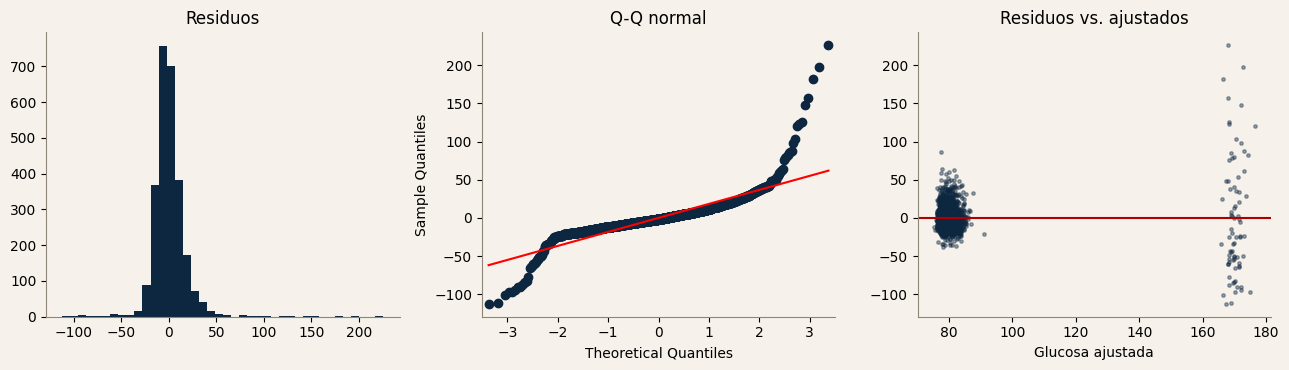

In [6]:
from sklearn.model_selection import KFold

pred = ["diabetes", "sysBP", "age", "male", "currentSmoker"]
y = tr_glu["glucose"]
X = sm.add_constant(tr_glu[pred].astype(float))
ols = sm.OLS(y, X).fit()

print(f"n = {int(ols.nobs)} | R² = {ols.rsquared:.3f} | R² ajustado = {ols.rsquared_adj:.3f} "
      f"| RMSE = {np.sqrt(ols.mse_resid):.2f} mg/dL")
display(ols.summary2().tables[1].round(3)[["Coef.", "Std.Err.", "P>|t|"]])

# Desempeño fuera de muestra (validación cruzada 5 pliegues) vs imputar la mediana
err_reg, err_med = [], []
for tr_i, va_i in KFold(5, shuffle=True, random_state=SEED).split(tr_glu):
    m = LinearRegression().fit(tr_glu.iloc[tr_i][pred], y.iloc[tr_i])
    err_reg.append(y.iloc[va_i] - m.predict(tr_glu.iloc[va_i][pred]))
    err_med.append(y.iloc[va_i] - y.iloc[tr_i].median())
rmse = lambda e: np.sqrt(np.mean(np.concatenate(e) ** 2))
print(f"RMSE validación cruzada -> regresión: {rmse(err_reg):.2f} | mediana: {rmse(err_med):.2f}")

# Supuestos: residuos
res, ajust = ols.resid, ols.fittedvalues
print(f"Asimetría de los residuos: {stats.skew(res):.2f}")
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
ax[0].hist(res, bins=40, color=NAVY); ax[0].set_title("Residuos")
sm.qqplot(res, line="s", ax=ax[1], markerfacecolor=NAVY, markeredgecolor=NAVY)
ax[1].set_title("Q-Q normal")
ax[2].scatter(ajust, res, s=6, alpha=.4, color=NAVY); ax[2].axhline(0, color=RED)
ax[2].set_title("Residuos vs. ajustados"); ax[2].set_xlabel("Glucosa ajustada")
plt.tight_layout(); plt.show()

Con el modelo ajustado, imputamos la glucosa en el entrenamiento y en la prueba **usando siempre el modelo del entrenamiento**. Generamos dos versiones. En la primera, cada valor faltante recibe la **predicción** de la regresión. En la segunda, a esa predicción se le suma un **residuo tomado al azar** de los residuos observados, de modo que los valores imputados conserven la dispersión real de la glucosa y no se amontonen en torno a un único valor. A ambas las acotamos entre el mínimo y el máximo observados en el entrenamiento, para no generar glucosas imposibles. También dejamos lista la imputación por mediana, que usaremos como comparación en la sección 1.3.

In [7]:
rng = np.random.default_rng(SEED)
modelo_imp = LinearRegression().fit(tr_glu[pred], y)      # mismo ajuste que el OLS
residuos = (y - modelo_imp.predict(tr_glu[pred])).to_numpy()
g_min, g_max, g_mediana = y.min(), y.max(), y.median()

def imputar(d):
    d = d.copy()
    falta = d["glucose"].isna()
    p = modelo_imp.predict(d.loc[falta, pred])
    d["glu_mediana"] = d["glucose"].fillna(g_mediana)
    d["glu_reg"] = d["glucose"]
    d.loc[falta, "glu_reg"] = np.clip(p, g_min, g_max)
    d["glu_reg_ruido"] = d["glucose"]
    d.loc[falta, "glu_reg_ruido"] = np.clip(p + rng.choice(residuos, falta.sum()), g_min, g_max)
    d["glu_imputada"] = falta
    return d

train_i, test_i = imputar(train), imputar(test)

print(f"Valores imputados: train {train_i.glu_imputada.sum()} ({train_i.glu_imputada.mean():.2%}) | "
      f"test {test_i.glu_imputada.sum()} ({test_i.glu_imputada.mean():.2%})")
print(f"Total: {train_i.glu_imputada.sum() + test_i.glu_imputada.sum()} (esperado: 388)")

# ¿Cómo quedan los valores imputados frente a los observados? (train)
obs = train_i.loc[~train_i.glu_imputada, "glucose"]
resumen = pd.DataFrame({
    "observada": obs.describe(),
    "mediana": train_i.loc[train_i.glu_imputada, "glu_mediana"].describe(),
    "regresión": train_i.loc[train_i.glu_imputada, "glu_reg"].describe(),
    "regresión + ruido": train_i.loc[train_i.glu_imputada, "glu_reg_ruido"].describe(),
}).round(1)
display(resumen)

Valores imputados: train 286 (9.64%) | test 102 (8.02%)
Total: 388 (esperado: 388)


,observada,mediana,regresión,regresión + ruido
count,2680.0,286.0,286.0,286.0
mean,82.1,78.0,80.3,80.3
std,23.9,0.0,9.3,22.9
min,40.0,78.0,76.2,40.0
25%,71.0,78.0,78.1,69.4
50%,78.0,78.0,79.2,77.1
75%,87.0,78.0,80.5,85.0
max,394.0,78.0,172.1,275.9


### Qué vemos

El modelo de imputación se ajustó con las 2.680 personas del entrenamiento que tienen glucosa registrada y explica el 41 % de su variación (R² = 0,408; error típico de 18,4 mg/dL). En validación cruzada, su error (18,6 mg/dL) es un 23 % menor que el de imputar la mediana (24,2 mg/dL), sin señales de sobreajuste. Sin embargo, esa mejora proviene casi por completo de la **diabetes**, que suma unos 89 mg/dL a la glucosa predicha; la presión sistólica aporta un efecto significativo pero mínimo (0,6 mg/dL por cada 10 mmHg), y la edad, el sexo y el tabaquismo no son significativos. En la práctica, el modelo distingue a las personas con diabetes del resto.

Los supuestos del modelo lineal se cumplen solo en parte: los residuos son asimétricos (asimetría = 2,14), tienen colas pesadas y su varianza es mucho mayor entre los diabéticos que entre los demás. Esto resta confiabilidad a los valores p de la tabla de coeficientes, pero no invalida el uso del modelo para imputar, ya que lo que necesitamos de él son predicciones promedio.

Se imputaron 388 valores de glucosa: 286 en el entrenamiento (9,64 %) y 102 en la prueba (8,02 %). Como casi todas esas personas no tienen diabetes, la regresión les asigna valores cercanos a 80 mg/dL (media 80,3; desviación estándar 9,3), de modo que la glucosa imputada es **mucho menos variable que la real** (desviación estándar 23,9). Es una mejora frente a la mediana, que repite un mismo valor (78,0) en todos, pero sigue siendo una compresión. La versión con ruido residual recupera la dispersión (22,9), aunque la exagera en las colas (máximo 275,9), porque sortea residuos que incluyen los de las personas diabéticas. Ambas versiones se comparan en la sección siguiente.

### 1.3 ¿Importa cómo tratemos la glucosa faltante?

Ya tenemos cuatro formas de resolver el problema: **eliminar** a las personas sin glucosa, imputar la **mediana**, imputar con la **regresión** e imputar con la regresión más **ruido residual**. Antes de elegir una para el resto del trabajo, las miramos con tres preguntas:

1. **¿Cuánta muestra y qué tipo de muestra queda?** Eliminar filas no solo achica el dataset: como la glucosa falta más en mujeres, también puede cambiar su composición.
2. **¿Qué le pasa a la distribución de la glucosa?** Una buena imputación no debería inventar una glucosa más uniforme (ni más extrema) que la real.
3. **¿Se conservan las relaciones que vimos en S1?** Lo que más importa es que la glucosa siga relacionada con la diabetes, la presión y la edad como antes. Una imputación que las diluye debilita los modelos que vienen después.

Todo se calcula sobre el conjunto de entrenamiento. La referencia para las relaciones es la glucosa realmente observada.

,n,% del train,% hombres,edad media,prevalencia CHD
Eliminación,2680,90.4%,44.4%,49.8,15.52%
Mediana,2966,100.0%,43.3%,49.7,15.21%
Regresión,2966,100.0%,43.3%,49.7,15.21%
Regresión + ruido,2966,100.0%,43.3%,49.7,15.21%


,media,desv. est.,asimetría,mediana,P95,máx
Eliminación,82.07,23.85,5.74,78.00,109.00,394.0
Mediana,81.68,22.71,6.07,78.00,107.00,394.0
Regresión,81.90,22.86,5.97,78.21,107.75,394.0
Regresión + ruido,81.90,23.77,5.65,78.00,108.00,394.0


,diabetes,sysBP,age,TenYearCHD
Eliminación,0.635,0.135,0.112,0.120
Mediana,0.623,0.129,0.108,0.116
Regresión,0.642,0.137,0.110,0.121
Regresión + ruido,0.615,0.135,0.098,0.114


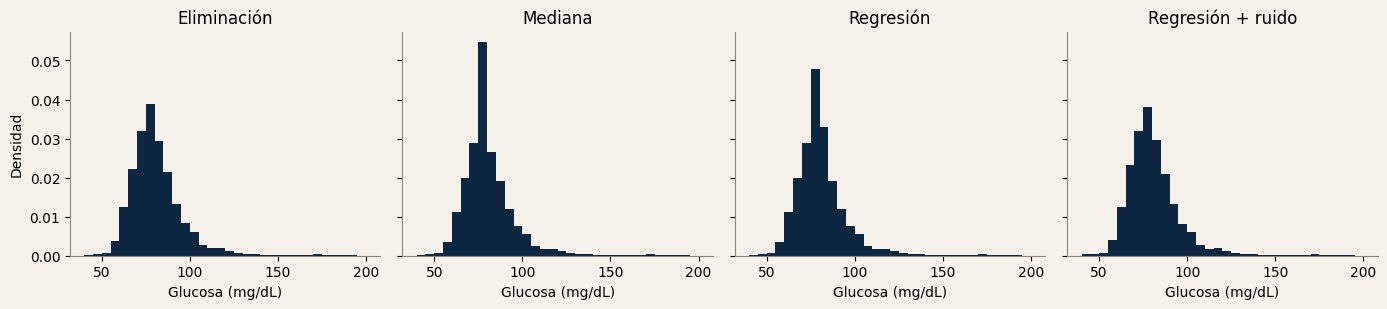

In [8]:
tr = train_i
elim = tr[~tr.glu_imputada]            # eliminación: solo casos con glucosa observada
estrategias = {
    "Eliminación":       (elim, elim["glucose"]),
    "Mediana":           (tr, tr["glu_mediana"]),
    "Regresión":         (tr, tr["glu_reg"]),
    "Regresión + ruido": (tr, tr["glu_reg_ruido"]),
}

# 1) Tamaño y composición de la muestra
t1 = pd.DataFrame({
    nom: {"n": len(d), "% del train": f"{len(d)/len(tr):.1%}",
          "% hombres": f"{d['male'].mean():.1%}",
          "edad media": f"{d['age'].mean():.1f}",
          "prevalencia CHD": f"{d[TARGET].mean():.2%}"}
    for nom, (d, g) in estrategias.items()}).T
display(t1)

# 2) Distribución de la glucosa
t2 = pd.DataFrame({
    nom: {"media": g.mean(), "desv. est.": g.std(), "asimetría": stats.skew(g),
          "mediana": g.median(), "P95": g.quantile(.95), "máx": g.max()}
    for nom, (d, g) in estrategias.items()}).T.round(2)
display(t2)

# 3) Relaciones con la glucosa (correlación de Pearson)
vars_rel = ["diabetes", "sysBP", "age", TARGET]
t3 = pd.DataFrame({
    nom: {v: d[v].corr(g) for v in vars_rel}
    for nom, (d, g) in estrategias.items()}).T.round(3)
display(t3)

# Gráfico: distribución de la glucosa por estrategia
fig, ax = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for a, (nom, (d, g)) in zip(ax, estrategias.items()):
    a.hist(g, bins=np.arange(40, 205, 5), color=NAVY, density=True)
    a.set_title(nom); a.set_xlabel("Glucosa (mg/dL)")
ax[0].set_ylabel("Densidad")
plt.tight_layout(); plt.show()

### Qué vemos

Como solo el 9,6 % de las glucosas del entrenamiento fue imputado, las diferencias entre estrategias son pequeñas, pero hay un patrón claro.

- **Muestra:** eliminar deja 2.680 de 2.966 personas (90,4 %) y cambia levemente su composición (hombres de 43,3 % a 44,4 %), coherente con que la glucosa falta más en mujeres. Las imputaciones conservan a todos.
- **Distribución:** la mediana crea un pico artificial en 78 mg/dL (desviación estándar 22,71 frente a 23,85 real). La regresión mejora algo (22,86), y la regresión con ruido es la más fiel (23,77).
- **Relaciones:** la regresión conserva las correlaciones de S1 (diferencias menores a 0,01), la mediana las debilita levemente y la versión con ruido es la que más las diluye. La correlación con la enfermedad coronaria, que no entró en la imputación, se mantiene (0,121 frente a 0,120).

**Estrategia elegida:** imputación por regresión determinista. Conserva toda la muestra, preserva las relaciones de S1 y no depende del azar. La eliminación queda como referencia, y la mediana y la regresión con ruido como análisis de sensibilidad en la sección 3.

## 2. Clasificación mediante regresión logística (30 pts + 30 pts de bootstrap)
### 2.1 Preparación de datos informada por S1
Partimos de `train_i`/`test_i` (1.2), con la glucosa imputada por regresión. Los faltantes menores de las demás variables (ninguno por encima del 2,5 %, no son el foco de esta sección) se resuelven con la mediana del entrenamiento, con una excepción: los 29 faltantes de `cigsPerDay` son todos fumadores actuales, así que se imputan con la mediana de los **fumadores** (20 cigarrillos) y no con la general (0, porque más de la mitad no fuma), que les asignaría «cero cigarrillos» a personas que fuman. Se acota la cola de la glucosa observada al percentil 99 del entrenamiento, como en S2 y F2, y se estandarizan todos los predictores con la media y la desviación del entrenamiento; por eso los coeficientes y odds ratios que siguen son **por cada desviación estándar** de la variable. `education` se excluye: es ordinal, tiene 105 faltantes propios y una asociación débil con el desenlace (verificado abajo).

In [9]:
# Correlación de education con el desenlace, para justificar su exclusión
educ = df[["education", TARGET]].dropna()
print(f"Correlación education-TenYearCHD (S1): {educ['education'].corr(educ[TARGET]):.3f} (n={len(educ)})")

candidatos_s3 = ["male", "age", "currentSmoker", "cigsPerDay", "BPMeds", "prevalentStroke",
                 "prevalentHyp", "diabetes", "totChol", "sysBP", "diaBP", "BMI", "heartRate", "glucose"]

# Dataset final: la glucosa es la imputada por regresión (1.2); el resto son faltantes menores
train_f, test_f = train_i.copy(), test_i.copy()
train_f["glucose"] = train_f["glu_reg"]
test_f["glucose"] = test_f["glu_reg"]

# cigsPerDay: los faltantes son todos fumadores actuales, asi que NO se imputa con la mediana general
# (que es 0 porque la mitad no fuma) sino con la mediana de los fumadores del train (como en F2).
assert df.loc[df["cigsPerDay"].isna(), "currentSmoker"].eq(1).all()
med_cigs_general = train_f["cigsPerDay"].median()
med_cigs_fumadores = train_f.loc[train_f["currentSmoker"] == 1, "cigsPerDay"].median()
print(f"cigsPerDay: mediana general del train = {med_cigs_general:.0f} | mediana de fumadores = {med_cigs_fumadores:.0f}")

menores = ["BPMeds", "totChol", "BMI", "heartRate"]
medianas_menores = train_f[menores].median()
for d in (train_f, test_f):
    d[menores] = d[menores].fillna(medianas_menores)
    d["cigsPerDay"] = d["cigsPerDay"].fillna(med_cigs_fumadores)
print("Faltantes restantes en los predictores (train, test):",
      int(train_f[candidatos_s3].isna().sum().sum()), int(test_f[candidatos_s3].isna().sum().sum()))

# Outliers: tope de glucosa al P99 de train, calculado solo con los casos observados (como en S2/F2)
tope_glu = train_f.loc[~train_f.glu_imputada, "glucose"].quantile(0.99)
for d in (train_f, test_f):
    d["glucose"] = d["glucose"].clip(upper=tope_glu)
print(f"Tope de glucosa (P99 de train, casos observados): {tope_glu:.1f} mg/dL")

# Estandarización con media/desviación del train
X_train = train_f[candidatos_s3].astype(float)
X_test = test_f[candidatos_s3].astype(float)
scaler_s3 = StandardScaler().fit(X_train)
X_train_sc = pd.DataFrame(scaler_s3.transform(X_train), columns=candidatos_s3, index=X_train.index)
X_test_sc = pd.DataFrame(scaler_s3.transform(X_test), columns=candidatos_s3, index=X_test.index)
y_train, y_test = train_f[TARGET], test_f[TARGET]

X_train_sc.describe().round(2).loc[["mean", "std"]]

Correlación education-TenYearCHD (S1): -0.054 (n=4133)
cigsPerDay: mediana general del train = 0 | mediana de fumadores = 20
Faltantes restantes en los predictores (train, test): 0 0
Tope de glucosa (P99 de train, casos observados): 187.1 mg/dL


,male,age,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose
mean,-0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,0.0,-0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


### 2.2 Tres modelos logísticos
Construimos tres modelos con criterios de selección distintos, sobre los mismos datos (2.1):

1. **Modelo 1, validado:** solo edad y presión sistólica, las dos variables que S1 identificó como más asociadas al desenlace y que S2 confirmó como estables por bootstrap.
2. **Modelo 2, selección hacia adelante por AIC:** partiendo sin variables, se agrega en cada paso la que más reduce el AIC, sobre los 14 candidatos, hasta que ninguna lo mejora.
3. **Modelo 3, reducido:** parte del Modelo 2 y va quitando la variable cuya salida más reduce el BIC, que penaliza la complejidad con más fuerza que el AIC, hasta que ya no mejora.

En los tres, el odds ratio (OR) indica cuánto se multiplican las odds de enfermedad coronaria por cada aumento de una desviación estándar del predictor.

In [10]:
# Modelo 1: las dos variables que S1 identifico y S2 valido por bootstrap (edad y presion sistolica)
vars_m1 = ["age", "sysBP"]

def ajustar(cols, nombre):
    m = sm.Logit(y_train, sm.add_constant(X_train_sc[cols])).fit(disp=0)
    print(f"{nombre}: {len(cols)} variables | AIC = {m.aic:.1f} | BIC = {m.bic:.1f} | pseudo R² = {m.prsquared:.3f}")
    return m

def tabla_or(m):
    # Los predictores estan estandarizados: el OR es el cambio en las odds por +1 desviacion estandar
    ic = m.conf_int()
    return pd.DataFrame({"Coef.": m.params, "OR (por DE)": np.exp(m.params),
                         "IC95% inf": np.exp(ic[0]), "IC95% sup": np.exp(ic[1]),
                         "p": m.pvalues}).round(3)

m1 = ajustar(vars_m1, "Modelo 1 (validado S1/S2: edad y sysBP)")
print(tabla_or(m1))

Modelo 1 (validado S1/S2: edad y sysBP): 2 variables | AIC = 2306.3 | BIC = 2324.3 | pseudo R² = 0.090
       Coef.  OR (por DE)  IC95% inf  IC95% sup    p
const -1.919        0.147      0.131      0.165  0.0
age    0.534        1.706      1.520      1.914  0.0
sysBP  0.386        1.471      1.329      1.628  0.0


In [11]:
# Modelo 2: seleccion hacia adelante (forward stepwise) por AIC sobre los 14 candidatos de 2.1
def forward_aic(X, y, candidatos):
    seleccion, restante = [], list(candidatos)
    aic_actual = sm.Logit(y, sm.add_constant(pd.Series(1.0, index=X.index, name="const"))).fit(disp=0).aic
    trayectoria = []
    while restante:
        aics = {c: sm.Logit(y, sm.add_constant(X[seleccion + [c]])).fit(disp=0).aic for c in restante}
        mejor_var = min(aics, key=aics.get)
        if aics[mejor_var] < aic_actual:
            aic_actual = aics[mejor_var]
            seleccion.append(mejor_var)
            restante.remove(mejor_var)
            trayectoria.append((mejor_var, round(aic_actual, 1)))
        else:
            break
    return seleccion, trayectoria

vars_m2, trayectoria_m2 = forward_aic(X_train_sc, y_train, candidatos_s3)
print("Orden de incorporación (variable, AIC acumulado):")
for paso, (v, a) in enumerate(trayectoria_m2, 1):
    print(f"  {paso}. {v:16s} AIC = {a}")

m2 = ajustar(vars_m2, "Modelo 2 (seleccion hacia adelante por AIC)")
print(tabla_or(m2))

Orden de incorporación (variable, AIC acumulado):
  1. age              AIC = 2360.6
  2. sysBP            AIC = 2306.3
  3. cigsPerDay       AIC = 2265.0
  4. glucose          AIC = 2253.6
  5. male             AIC = 2243.3
  6. prevalentStroke  AIC = 2238.4
  7. totChol          AIC = 2235.6
  8. BPMeds           AIC = 2233.7
Modelo 2 (seleccion hacia adelante por AIC): 8 variables | AIC = 2233.7 | BIC = 2287.7 | pseudo R² = 0.124
                 Coef.  OR (por DE)  IC95% inf  IC95% sup      p
const           -2.007        0.134      0.119      0.152  0.000
age              0.586        1.797      1.591      2.030  0.000
sysBP            0.363        1.438      1.292      1.601  0.000
cigsPerDay       0.294        1.342      1.204      1.496  0.000
glucose          0.168        1.183      1.081      1.294  0.000
male             0.221        1.247      1.112      1.400  0.000
prevalentStroke  0.109        1.115      1.030      1.209  0.008
totChol          0.118        1.126      1.

In [12]:
# Modelo 3: version REDUCIDA del Modelo 2, por eliminacion hacia atras guiada por BIC.
# Se parte de las 8 variables del Modelo 2 y se quita, paso a paso, la variable cuya salida mas
# reduce el BIC; se detiene cuando ninguna salida lo mejora. El BIC penaliza mas la complejidad que el AIC.
def backward_bic(X, y, cols):
    sel = list(cols)
    bic_act = sm.Logit(y, sm.add_constant(X[sel])).fit(disp=0).bic
    trayectoria = []
    while len(sel) > 1:
        bics = {c: sm.Logit(y, sm.add_constant(X[[v for v in sel if v != c]])).fit(disp=0).bic for c in sel}
        peor = min(bics, key=bics.get)
        if bics[peor] < bic_act:
            bic_act = bics[peor]; sel.remove(peor); trayectoria.append((peor, round(bic_act, 1)))
        else:
            break
    return sel, trayectoria

vars_m3, trayectoria_m3 = backward_bic(X_train_sc, y_train, vars_m2)
print("Variables eliminadas desde el Modelo 2 (variable, BIC acumulado):")
for paso, (v, b) in enumerate(trayectoria_m3, 1):
    print(f"  {paso}. {v:16s} BIC = {b}")

m3 = ajustar(vars_m3, "Modelo 3 (reducido, eliminacion hacia atras por BIC)")
print(tabla_or(m3))

# Comparacion de los tres modelos (y del modelo completo como referencia)
m_completo = ajustar(candidatos_s3, "Modelo completo (14 variables, referencia)")
comparacion = pd.DataFrame({
    "N variables": [len(vars_m1), len(vars_m2), len(vars_m3), len(candidatos_s3)],
    "AIC": [m1.aic, m2.aic, m3.aic, m_completo.aic],
    "BIC": [m1.bic, m2.bic, m3.bic, m_completo.bic],
    "pseudo R²": [m1.prsquared, m2.prsquared, m3.prsquared, m_completo.prsquared],
}, index=["Modelo 1 (validado)", "Modelo 2 (forward AIC)", "Modelo 3 (reducido BIC)", "Completo (referencia)"]).round(3)
print("\n", comparacion)
print("\nVariables M1:", vars_m1, "\nVariables M2:", vars_m2, "\nVariables M3:", vars_m3)

Variables eliminadas desde el Modelo 2 (variable, BIC acumulado):
  1. BPMeds           BIC = 2283.5
  2. totChol          BIC = 2280.3
  3. prevalentStroke  BIC = 2279.3
Modelo 3 (reducido, eliminacion hacia atras por BIC): 5 variables | AIC = 2243.3 | BIC = 2279.3 | pseudo R² = 0.118
            Coef.  OR (por DE)  IC95% inf  IC95% sup    p
const      -1.993        0.136      0.120      0.154  0.0
age         0.608        1.837      1.629      2.073  0.0
sysBP       0.400        1.493      1.345      1.656  0.0
cigsPerDay  0.291        1.338      1.201      1.490  0.0
glucose     0.166        1.181      1.080      1.291  0.0
male        0.203        1.225      1.093      1.372  0.0
Modelo completo (14 variables, referencia): 14 variables | AIC = 2243.3 | BIC = 2333.2 | pseudo R² = 0.125

                          N variables       AIC       BIC  pseudo R²
Modelo 1 (validado)                2  2306.325  2324.310      0.090
Modelo 2 (forward AIC)             8  2233.713  2287.668      

### Qué vemos

**Modelo 1 (edad y sistólica).** Ambas variables son muy significativas (OR por desviación estándar de 1,71 y 1,47), pero el modelo es pobre: AIC = 2306,3 y pseudo R² = 0,090.

**Modelo 2 (hacia adelante por AIC).** Incorpora ocho variables. En sus cinco primeros pasos, con un algoritmo que no conocía nuestras decisiones previas, elige edad, sistólica, cigarrillos, glucosa y sexo, que son las cinco de F2. Las tres que suma después (antecedente de ACV, colesterol total y medicación antihipertensiva) tienen efectos pequeños (OR de 1,09 a 1,13) y valores p de 0,008, 0,031 y 0,045, es decir, justo en el borde de la significancia. Mejora el AIC (2233,7), pero empeora el BIC (2287,7).

**Modelo 3 (reducido por BIC).** Al partir del Modelo 2, el procedimiento elimina, en este orden, la medicación, el colesterol y el ACV, y se detiene en **cinco variables: edad, sistólica, cigarrillos, glucosa y sexo** (AIC = 2243,3; BIC = 2279,3; pseudo R² = 0,118). Son exactamente las de F2, a las que llegamos ahora por dos caminos independientes, uno de criterio estadístico y otro de S1 y S2. Los odds ratios por desviación estándar son: edad 1,84, sistólica 1,49, cigarrillos 1,34, glucosa 1,18 y sexo 1,23.

**Comparación.** Pasar de dos a cinco variables mejora el AIC en 63 puntos (de 2306,3 a 2243,3): las tres variables añadidas importan. Pasar de cinco a ocho lo mejora en solo 9,6 puntos y empeora el BIC. El modelo completo de 14 variables no mejora el AIC del Modelo 3 (2243,3) y tiene el peor BIC (2333,2): las variables restantes no aportan.

### 2.3 Ponderación de clases
En F2, con umbral 0,5 y sin ponderar, el recall fue de solo 4,7 %: el modelo casi nunca predice la clase minoritaria porque su probabilidad rara vez supera 0,5. Ponderamos cada observación con el peso inverso a la frecuencia de su clase (igual que `class_weight='balanced'` de scikit-learn): 3,29 para los casos de CHD y 0,59 para los demás, de modo que los 451 casos de CHD del entrenamiento pesen tanto como los 2.515 sin CHD en la función de verosimilitud. Esto concuerda con el orden de magnitud que indicó el profesor (≈ 3,3).

In [13]:
# Peso balanceado por clase (igual formula que class_weight='balanced' de scikit-learn)
n = len(y_train); n1 = int(y_train.sum()); n0 = n - n1
w1, w0 = n / (2 * n1), n / (2 * n0)
print(f"Casos train: {n0} sin CHD, {n1} con CHD | peso clase 0 = {w0:.3f} | peso clase 1 = {w1:.3f}")
pesos = y_train.map({1: w1, 0: w0})

def ajustar_ponderado(cols, nombre):
    m = sm.GLM(y_train, sm.add_constant(X_train_sc[cols]), family=sm.families.Binomial(),
              freq_weights=pesos).fit()
    print(f"{nombre}: {len(cols)} variables (ponderado)")
    return m

m1_w = ajustar_ponderado(vars_m1, "Modelo 1 ponderado")
m2_w = ajustar_ponderado(vars_m2, "Modelo 2 ponderado")
m3_w = ajustar_ponderado(vars_m3, "Modelo 3 ponderado")

Casos train: 2515 sin CHD, 451 con CHD | peso clase 0 = 0.590 | peso clase 1 = 3.288
Modelo 1 ponderado: 2 variables (ponderado)
Modelo 2 ponderado: 8 variables (ponderado)
Modelo 3 ponderado: 5 variables (ponderado)


### 2.4 Evaluación de desempeño y selección del modelo final
Comparamos los tres modelos, con y sin ponderar, en train y test: AUC (no depende del umbral; mide si el ranking de riesgo generaliza) y, con umbral 0,5, accuracy, precision, recall y F1 (miden el punto de operación). Las curvas ROC de los tres modelos se muestran en un mismo gráfico, a la izquierda sin ponderar y a la derecha ponderados.

                 AUC train  AUC test  Accuracy  Precision  Recall      F1
Modelo                                                                   
M1 sin ponderar     0.7166    0.6737    0.8467     0.4375  0.0363  0.0670
M1 ponderado        0.7165    0.6732    0.6447     0.2285  0.5648  0.3254
M2 sin ponderar     0.7437    0.6987    0.8443     0.4074  0.0570  0.1000
M2 ponderado        0.7442    0.6969    0.6619     0.2463  0.5959  0.3485
M3 sin ponderar     0.7382    0.7031    0.8451     0.4091  0.0466  0.0837
M3 ponderado        0.7384    0.7020    0.6643     0.2489  0.6010  0.3520

Matriz de confusión (test, umbral 0,5):
M1 sin ponderar: TN=1070 FP=9 FN=186 TP=7
M1 ponderado: TN=711 FP=368 FN=84 TP=109
M2 sin ponderar: TN=1063 FP=16 FN=182 TP=11
M2 ponderado: TN=727 FP=352 FN=78 TP=115
M3 sin ponderar: TN=1066 FP=13 FN=184 TP=9
M3 ponderado: TN=729 FP=350 FN=77 TP=116


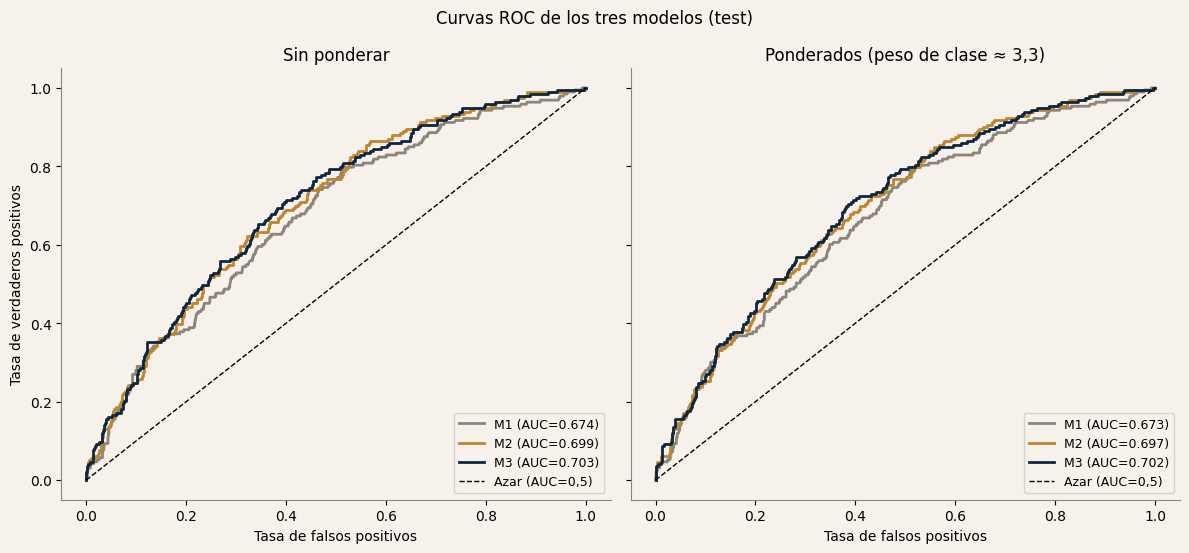

In [14]:
def predecir(m, cols, X):
    return m.predict(sm.add_constant(X[cols], has_constant="add"))

candidatos_modelos = {
    "M1 sin ponderar": (m1, vars_m1),   "M1 ponderado": (m1_w, vars_m1),
    "M2 sin ponderar": (m2, vars_m2),   "M2 ponderado": (m2_w, vars_m2),
    "M3 sin ponderar": (m3, vars_m3),   "M3 ponderado": (m3_w, vars_m3),
}

filas, curvas_roc = [], {}
for nombre, (m, cols) in candidatos_modelos.items():
    p_tr, p_te = predecir(m, cols, X_train_sc), predecir(m, cols, X_test_sc)
    pred_te = (p_te >= 0.5).astype(int)
    filas.append({
        "Modelo": nombre, "AUC train": roc_auc_score(y_train, p_tr), "AUC test": roc_auc_score(y_test, p_te),
        "Accuracy": accuracy_score(y_test, pred_te), "Precision": precision_score(y_test, pred_te, zero_division=0),
        "Recall": recall_score(y_test, pred_te), "F1": f1_score(y_test, pred_te),
    })
    curvas_roc[nombre] = roc_curve(y_test, p_te)

tabla_desempeno = pd.DataFrame(filas).set_index("Modelo").round(4)
print(tabla_desempeno)

print("\nMatriz de confusión (test, umbral 0,5):")
for nombre, (m, cols) in candidatos_modelos.items():
    cm = confusion_matrix(y_test, (predecir(m, cols, X_test_sc) >= 0.5).astype(int))
    print(f"{nombre}: TN={cm[0,0]} FP={cm[0,1]} FN={cm[1,0]} TP={cm[1,1]}")

# Curvas ROC de los tres modelos en un mismo grafico (a la izquierda sin ponderar, a la derecha ponderados)
colores = {"M1": GREY, "M2": OCHRE, "M3": NAVY}
fig, ax = plt.subplots(1, 2, figsize=(12, 5.6), sharey=True)
for a, sufijo, titulo in zip(ax, ["sin ponderar", "ponderado"], ["Sin ponderar", "Ponderados (peso de clase ≈ 3,3)"]):
    for k in ("M1", "M2", "M3"):
        nombre = f"{k} {sufijo}"; fpr, tpr, _ = curvas_roc[nombre]
        a.plot(fpr, tpr, color=colores[k], lw=2, label=f"{k} (AUC={tabla_desempeno.loc[nombre, 'AUC test']:.3f})")
    a.plot([0, 1], [0, 1], "k--", lw=1, label="Azar (AUC=0,5)")
    a.set_title(titulo); a.set_xlabel("Tasa de falsos positivos"); a.legend(loc="lower right", fontsize=9)
ax[0].set_ylabel("Tasa de verdaderos positivos")
fig.suptitle("Curvas ROC de los tres modelos (test)")
plt.tight_layout(); plt.show()

### Qué vemos

**La ponderación sube el recall sin cambiar el ranking.** Con el Modelo 3, el recall pasa de 4,7 % a **60,1 %** (de 9 a 116 de los 193 casos del test detectados), a costa de más falsos positivos (de 13 a 350) y menor accuracy (de 84,5 % a 66,4 %, que ya no es el espejismo de predecir siempre la clase mayoritaria: el modelo trivial acierta 84,8 %). El AUC apenas se mueve (0,703 a 0,702), porque la ponderación solo cambia el punto de corte sobre la misma curva ROC. Lo mismo ocurre con los otros dos modelos.

**Entre modelos.** El Modelo 1 queda claramente por debajo (AUC test 0,674; recall ponderado 56,5 %). El Modelo 2 mejora el entrenamiento (AUC 0,744) pero no el test (0,699 frente a 0,703 del Modelo 3): la diferencia entre train y test es mayor (con ponderación, 0,047 frente a 0,036), señal de que sus tres variables adicionales ajustan el entrenamiento sin generalizar mejor. En las curvas ROC, el Modelo 1 es la curva más baja y los modelos 2 y 3 casi se superponen.

**Modelo final: Modelo 3 ponderado** (edad, presión sistólica, sexo, cigarrillos por día y glucosa; peso de clase ≈ 3,3). Tiene el mejor AUC en test, el mayor recall y F1 entre los modelos ponderados (60,1 % y 0,352), y es más simple que el Modelo 2. El AUC de 0,70 es aceptable y no excelente: el modelo ordena razonablemente el riesgo, pero no separa bien a los casos de los no casos.

### 2.5 Estabilidad mediante bootstrap (30 pts)
Bootstrap no paramétrico (remuestreo de filas del train, con reemplazo) sobre el modelo final (Modelo 3 ponderado). En cada remuestra se recalcula el peso de clase (la proporción de CHD cambia con el remuestreo) y se reajusta el modelo completo, para que el bootstrap capture también la incertidumbre de la ponderación. Usamos 2.000 remuestras (≥ 1.000 pedido; menos que las 10.000 de S2 porque acá cada remuestra reajusta un modelo ponderado, más costoso que el estadístico simple de S2) y el IC percentil al 95 %, comparado con el IC de Wald tradicional. Los coeficientes están en unidades de desviación estándar, así que los OR son por desviación estándar.

In [15]:
B = 2000
rng_bs = np.random.default_rng(SEED)
n_train = len(X_train_sc)
nombres = ["const"] + vars_m3
coefs_bs = np.full((B, len(nombres)), np.nan)

for b in range(B):
    idx = rng_bs.integers(0, n_train, n_train)
    Xb = X_train_sc.iloc[idx][vars_m3].reset_index(drop=True)
    yb = y_train.iloc[idx].reset_index(drop=True)
    n1b = int(yb.sum())
    if n1b == 0 or n1b == len(yb):
        continue  # remuestra degenerada (sin ambas clases); se omite
    wb = yb.map({1: len(yb) / (2 * n1b), 0: len(yb) / (2 * (len(yb) - n1b))})
    mb = sm.GLM(yb, sm.add_constant(Xb, has_constant="add"), family=sm.families.Binomial(),
               freq_weights=wb).fit()
    coefs_bs[b] = mb.params.reindex(nombres).values

coefs_bs_df = pd.DataFrame(coefs_bs, columns=nombres).dropna()
print(f"Remuestras válidas: {len(coefs_bs_df)} de {B}")

ic_boot = coefs_bs_df.quantile([0.025, 0.975]).T
ic_boot.columns = ["boot 2.5%", "boot 97.5%"]
ic_boot.insert(0, "coef.", m3_w.params[nombres].values)

ic_wald = m3_w.conf_int().loc[nombres]
ic_wald.columns = ["Wald 2.5%", "Wald 97.5%"]

tabla_boot = pd.concat([ic_boot, ic_wald], axis=1).round(4)
tabla_boot["OR"] = np.exp(tabla_boot["coef."]).round(3)
tabla_boot["OR boot [IC95%]"] = [f"[{np.exp(lo):.3f}, {np.exp(hi):.3f}]"
                                 for lo, hi in zip(tabla_boot["boot 2.5%"], tabla_boot["boot 97.5%"])]
print(tabla_boot)

Remuestras válidas: 2000 de 2000
             coef.  boot 2.5%  boot 97.5%  Wald 2.5%  Wald 97.5%     OR  \
const      -0.2745    -0.3577     -0.2122    -0.3576     -0.1914  0.760   
age         0.6396     0.5288      0.7629     0.5490      0.7302  1.896   
sysBP       0.3824     0.2765      0.4945     0.3001      0.4646  1.466   
cigsPerDay  0.2946     0.1793      0.4033     0.2104      0.3788  1.343   
glucose     0.1516     0.0521      0.2449     0.0806      0.2227  1.164   
male        0.1801     0.0565      0.3008     0.0967      0.2635  1.197   

           OR boot [IC95%]  
const       [0.699, 0.809]  
age         [1.697, 2.144]  
sysBP       [1.319, 1.640]  
cigsPerDay  [1.196, 1.497]  
glucose     [1.053, 1.277]  
male        [1.058, 1.351]  


### Qué vemos

Las 2.000 remuestras convergieron todas. Los cinco coeficientes son **estables**: ningún IC bootstrap cruza el cero ni su OR cruza 1. Los odds ratios por desviación estándar, con su IC bootstrap al 95 %, son: edad 1,90 [1,70; 2,14], sistólica 1,47 [1,32; 1,64], cigarrillos 1,34 [1,20; 1,50], sexo 1,20 [1,06; 1,35] y glucosa 1,16 [1,05; 1,28].

Los parámetros menos estables son **glucosa y sexo**: sus límites inferiores son los más cercanos a cero (0,052 y 0,057 en coeficiente). Para los cinco predictores el IC bootstrap es más ancho que el de Wald (por ejemplo, sexo: [0,057; 0,301] frente a [0,097; 0,264]), que asume normalidad asintótica y no recoge la incertidumbre de recalcular el peso de clase en cada remuestra. Solo el intercepto va en sentido contrario (algo más angosto). Ningún parámetro cambia de signo ni de significancia entre ambos métodos: el modelo final es robusto al remuestreo.

### 2.6 Diagnóstico de supuestos
Diagnósticos de especificación (VIF, linealidad en el logit, influyentes, residuos) sobre el **Modelo 3 sin ponderar**: la ponderación de 2.3 es una decisión de calibración del umbral, no cambia la especificación del modelo, y complica las medidas de influencia, pensadas para observaciones con igual peso. Se verifica también qué pasaría si se incluyeran la diastólica y la hipertensión, excluidas por colinealidad con la sistólica.

In [16]:
# 1) VIF del Modelo 3 (final), y verificacion de lo que pasaria con diaBP y prevalentHyp incluidas
X_vif = sm.add_constant(X_train_sc[vars_m3])
vif_m3 = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],
}).round(2)
print("VIF del Modelo 3 (final):")
print(vif_m3)

vars_check = vars_m3 + ["diaBP", "prevalentHyp"]
X_vif2 = sm.add_constant(X_train_sc[vars_check])
vif_check = pd.DataFrame({
    "Variable": X_vif2.columns,
    "VIF": [variance_inflation_factor(X_vif2.values, i) for i in range(X_vif2.shape[1])],
}).round(2)
print("\nVIF si se agregaran diaBP y prevalentHyp (solo para verificar la exclusion de 2.1/2.2):")
print(vif_check)

VIF del Modelo 3 (final):
     Variable   VIF
0       const  1.00
1         age  1.23
2       sysBP  1.20
3  cigsPerDay  1.16
4     glucose  1.03
5        male  1.12

VIF si se agregaran diaBP y prevalentHyp (solo para verificar la exclusion de 2.1/2.2):
       Variable   VIF
0         const  1.00
1           age  1.28
2         sysBP  3.69
3    cigsPerDay  1.17
4       glucose  1.04
5          male  1.15
6         diaBP  2.82
7  prevalentHyp  2.01


Terminos de interaccion (Box-Tidwell): p < 0.05 sugiere no linealidad en el logit
                            Coef.   P>|z|
age_x_lnage               -0.0825  0.0114
sysBP_x_lnsysBP            0.0095  0.2660
cigsPerDay_x_lncigsPerDay -0.0037  0.7122
glucose_x_lnglucose        0.0121  0.0980

Observaciones influyentes de S2, presencia y distancia de Cook en el train de S3:
  fila 481: en train, Cook's D = 0.00077
  fila 2909: no esta en el train de S3 (quedo en test)
  fila 3160: no esta en el train de S3 (quedo en test)
  fila 2197: en train, Cook's D = 0.00121
  fila 781: no esta en el train de S3 (quedo en test)

Umbral de referencia (4/n): 0.00135 | máx. Cook's D observado: 0.00961


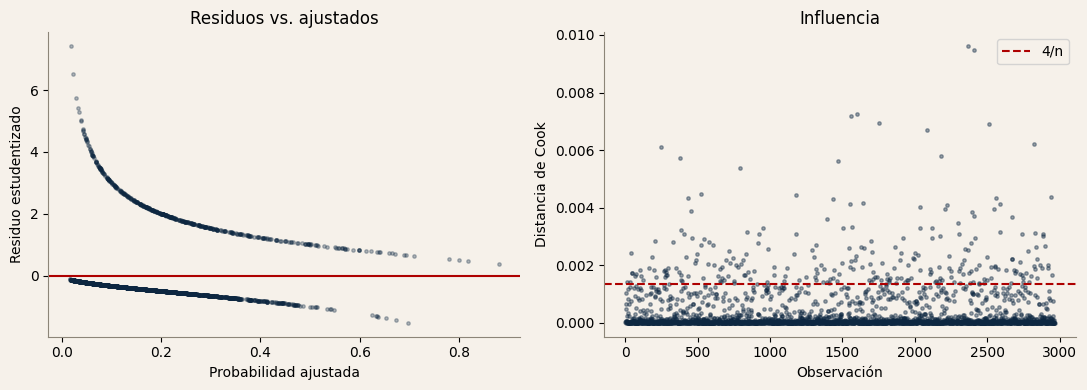

In [17]:
# 2) Linealidad en el logit: prueba de Box-Tidwell (termino x*ln(x) por variable continua positiva)
# Las variables estandarizadas pueden ser negativas; se usa el valor original (positivo) de cada una.
continuas_m3 = [v for v in vars_m3 if train_f[v].nunique() > 2]   # solo variables continuas
X_bt = X_train_sc[vars_m3].copy()
for v in continuas_m3:
    x_orig = train_f.loc[X_bt.index, v].astype(float)
    x_pos = x_orig - x_orig.min() + 1          # desplazar a positivo para poder tomar logaritmo
    X_bt[f"{v}_x_ln{v}"] = x_pos * np.log(x_pos)

m_bt = sm.Logit(y_train, sm.add_constant(X_bt)).fit(disp=0)
print("Terminos de interaccion (Box-Tidwell): p < 0.05 sugiere no linealidad en el logit")
print(m_bt.summary2().tables[1].round(4).loc[[f"{v}_x_ln{v}" for v in continuas_m3], ["Coef.", "P>|z|"]])

# 3) Observaciones influyentes: las que S2 identifico (filas 481, 2909, 3160, 2197, 781)
infl = m3.get_influence()
cooks = infl.cooks_distance[0]
idx_train = X_train_sc.index
filas_s2 = [481, 2909, 3160, 2197, 781]
print("\nObservaciones influyentes de S2, presencia y distancia de Cook en el train de S3:")
for f in filas_s2:
    if f in idx_train:
        pos = idx_train.get_loc(f)
        print(f"  fila {f}: en train, Cook's D = {cooks[pos]:.5f}")
    else:
        print(f"  fila {f}: no esta en el train de S3 (quedo en test)")
print(f"\nUmbral de referencia (4/n): {4/len(idx_train):.5f} | máx. Cook's D observado: {cooks.max():.5f}")

# 4) Residuos
res_pearson = infl.resid_studentized
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(m3.predict(), res_pearson, s=6, alpha=.3, color=NAVY)
ax[0].axhline(0, color=RED); ax[0].set_xlabel("Probabilidad ajustada"); ax[0].set_ylabel("Residuo estudentizado")
ax[0].set_title("Residuos vs. ajustados")
ax[1].scatter(range(len(cooks)), cooks, s=6, alpha=.4, color=NAVY)
ax[1].axhline(4/len(idx_train), color=RED, ls="--", label="4/n")
ax[1].set_xlabel("Observación"); ax[1].set_ylabel("Distancia de Cook"); ax[1].set_title("Influencia")
ax[1].legend()
plt.tight_layout(); plt.show()

### Qué vemos

**VIF.** Las cinco variables del Modelo 3 tienen VIF entre 1,03 y 1,23: no hay multicolinealidad. Si se agregaran la diastólica y la hipertensión prevalente, el VIF de la sistólica subiría de 1,20 a 3,69 (el de la diastólica sería 2,82 y el de la hipertensión 2,01). Sigue bajo el umbral de 5, pero es un salto fuerte, y respalda haber dejado solo una de las tres variables de presión.

**Linealidad en el logit.** La prueba de Box-Tidwell detecta una no linealidad leve en la **edad** (p = 0,011, que se mantiene significativa aun corrigiendo por las cuatro pruebas hechas: umbral 0,0125). Presión sistólica (p = 0,27), cigarrillos (p = 0,71) y glucosa (p = 0,098) no muestran evidencia al 5 %. No se corrige aquí, porque un término cuadrático cambiaría la interpretación directa del odds ratio, pero queda documentado como limitación.

**Observaciones influyentes.** De las cinco filas que S2 había identificado, solo la 481 y la 2197 caen en el entrenamiento de S3 (las otras tres quedaron en el test por la partición); ambas quedan bajo el umbral de referencia 4/n = 0,00135 (Cook's D de 0,00077 y 0,00121). Hay otras observaciones sobre el umbral, pero el máximo es 0,0096, muy lejos de 1: ningún punto domina el ajuste.

**Residuos.** Los residuos estudentizados contra la probabilidad ajustada no muestran un patrón sistemático preocupante.

## 3. Análisis comparativo del impacto de la imputación (9 pts)
Reajustamos el modelo final (Modelo 3 ponderado, las mismas 5 variables) con tres versiones del dataset: **eliminación** (solo casos con glucosa observada), **mediana** e **imputación por regresión** (la elegida en 1.3). Las tres parten de la misma partición 70/30; la eliminación quita de ambos conjuntos las filas sin glucosa observada, y cada estrategia re-estandariza y reajusta su propio modelo ponderado. Como el test de la eliminación es más pequeño (1.170 en lugar de 1.272), sus métricas no son estrictamente comparables con las otras dos.

In [18]:
def construir_estrategia(glucose_col=None, eliminar=False):
    tr, te = train_i.copy(), test_i.copy()
    if eliminar:
        tr, te = tr[~tr.glu_imputada].copy(), te[~te.glu_imputada].copy()
    else:
        tr["glucose"], te["glucose"] = tr[glucose_col], te[glucose_col]
    tr["glucose"] = tr["glucose"].clip(upper=tope_glu)
    te["glucose"] = te["glucose"].clip(upper=tope_glu)
    for d in (tr, te):    # mismo tratamiento de cigsPerDay que en 2.1 (mediana de los fumadores del train)
        d["cigsPerDay"] = d["cigsPerDay"].fillna(med_cigs_fumadores)
        for v in menores:
            d[v] = d[v].fillna(medianas_menores[v])
    return tr, te

estrategias_mod = {
    "Eliminación": construir_estrategia(eliminar=True),
    "Mediana":     construir_estrategia("glu_mediana"),
    "Regresión":   construir_estrategia("glu_reg"),
}

filas3, coefs3 = [], {}
for nombre, (tr, te) in estrategias_mod.items():
    sca = StandardScaler().fit(tr[vars_m3].astype(float))
    Xtr = pd.DataFrame(sca.transform(tr[vars_m3].astype(float)), columns=vars_m3, index=tr.index)
    Xte = pd.DataFrame(sca.transform(te[vars_m3].astype(float)), columns=vars_m3, index=te.index)
    ytr, yte = tr[TARGET], te[TARGET]
    n1, n0 = int(ytr.sum()), len(ytr) - int(ytr.sum())
    w = ytr.map({1: len(ytr) / (2 * n1), 0: len(ytr) / (2 * n0)})
    m = sm.GLM(ytr, sm.add_constant(Xtr), family=sm.families.Binomial(), freq_weights=w).fit()
    p_tr = m.predict(sm.add_constant(Xtr, has_constant="add"))
    p_te = m.predict(sm.add_constant(Xte, has_constant="add"))
    pred_te = (p_te >= 0.5).astype(int)
    filas3.append({
        "Estrategia": nombre, "n train": len(tr), "n test": len(te),
        "AUC train": roc_auc_score(ytr, p_tr), "AUC test": roc_auc_score(yte, p_te),
        "Accuracy test": accuracy_score(yte, pred_te), "Recall test": recall_score(yte, pred_te),
    })
    coefs3[nombre] = m.params

tabla3 = pd.DataFrame(filas3).set_index("Estrategia").round(4)
print(tabla3)

coefs_df3 = pd.DataFrame(coefs3).round(4)
print("\nCoeficientes por estrategia:")
print(coefs_df3)
print("\nOdds ratios por estrategia:")
print(np.exp(coefs_df3).round(3))

             n train  n test  AUC train  AUC test  Accuracy test  Recall test
Estrategia                                                                   
Eliminación     2680    1170     0.7459    0.7032         0.6667       0.6011
Mediana         2966    1272     0.7378    0.7023         0.6612       0.6010
Regresión       2966    1272     0.7384    0.7020         0.6643       0.6010

Coeficientes por estrategia:
            Eliminación  Mediana  Regresión
const           -0.2924  -0.2728    -0.2745
age              0.6701   0.6385     0.6396
sysBP            0.4020   0.3856     0.3824
cigsPerDay       0.2939   0.2951     0.2946
glucose          0.1397   0.1365     0.1516
male             0.1963   0.1783     0.1801

Odds ratios por estrategia:
            Eliminación  Mediana  Regresión
const             0.746    0.761      0.760
age               1.954    1.894      1.896
sysBP             1.495    1.470      1.466
cigsPerDay        1.342    1.343      1.343
glucose           1.150

### Qué vemos

**La estrategia de imputación casi no cambia las conclusiones.** El AUC en test es prácticamente idéntico (0,703 eliminación, 0,702 mediana, 0,702 regresión) y el recall es el mismo en las tres (60,1 %). Los odds ratios varían poco: el de glucosa pasa de 1,15 (eliminación y mediana) a 1,16 (regresión), y el de edad es el que más se mueve (1,95 con eliminación frente a 1,89 con las otras dos). Es coherente con que la glucosa es la única variable que cada estrategia trata distinto.

**La diferencia real es el tamaño muestral.** La eliminación pierde 286 personas de entrenamiento y 102 de prueba (exactamente las imputadas en 1.2); eso no empeora el AUC medible aquí, pero reduce la precisión de los IC y, como mostró 1.1, sesga levemente la composición por sexo.

**Recomendación.** Se confirma 1.3: la imputación por regresión es la opción defendible por defecto, porque conserva toda la muestra sin cambiar las conclusiones. Con tan pocos valores imputados (9,6 % de una sola variable) las tres estrategias no se distinguen; con más faltantes, la brecha probablemente sería mayor.

## 4. Síntesis integrada (parte del informe final, 9 pts)

**Cómo cada fase informó a la siguiente.** S1 encontró que la edad y la presión sistólica eran los predictores más asociados a CHD, y describió los faltantes y los valores extremos. S2 validó por bootstrap que esas correlaciones eran estables, y mostró que la diastólica y la hipertensión son colineales con la sistólica. F2 tradujo eso en un primer modelo logístico de 5 variables, con AUC de 0,703 pero recall de solo 4,7 % al no ponderar. En S3 construimos tres modelos (edad y sistólica; hacia adelante por AIC; reducido por BIC): el reducido coincide exactamente con las 5 variables de F2, a las que ahora llegamos por un camino estadístico independiente. Tratamos la glucosa con una imputación más honesta que la mediana (1.1-1.3) y resolvimos el problema de recall de F2 ponderando las clases (2.3-2.4).

**Resultados principales.** El modelo final (edad, presión sistólica, sexo, cigarrillos por día y glucosa, ponderado por clase) tiene AUC 0,738 en train y 0,702 en test, y sube el recall a 60,1 %, a costa de más falsos positivos (precision de 25 %). Es estable al bootstrap (ningún IC cruza el cero; glucosa y sexo son los menos estables) y no tiene multicolinealidad (VIF ≤ 1,23). La elección de imputación no cambia estas conclusiones (sección 3).

**Limitaciones.** El AUC de 0,70 es aceptable pero no alto. La prueba de Box-Tidwell detecta una no linealidad leve en la edad, no corregida aquí. El bootstrap usó 2.000 remuestras (no 10.000 como en S2). El modelo es un único logístico lineal, sin compararlo con alternativas no paramétricas. La imputación de la glucosa, aunque mejor que la mediana, comprime su variabilidad real (1.2), y el mecanismo MAR es un supuesto no verificable.

**Recomendaciones.** Para un uso real convendría: (1) explorar un término no lineal para la edad (cuadrático o splines); (2) elegir el umbral de decisión según el costo relativo de un falso negativo frente a un falso positivo, en vez de 0,5; (3) comparar contra un modelo no lineal para medir cuánto se pierde por restringirse a lo lineal.

## Checklist de entrega
- [x] Ejecuta sin errores de principio a fin y con salidas visibles
- [x] Faltantes: referencia a S1, imputación por regresión y comparación de tres estrategias
- [x] Tres modelos logísticos con odds ratios y variables justificadas con S1/S2
- [x] Ponderación de clase / umbral y efecto sobre el recall
- [x] Matrices de confusión (train y test), métricas y ROC comparada
- [x] Bootstrap de coeficientes y odds ratios con IC al 95 %
- [x] VIF, linealidad en el logit, influyentes y residuos
- [x] Comparación del modelo final con los tres datasets
- [ ] Informe final (máx. 10 págs.) y presentación (10 min)
- [x] Semilla fijada (SEED = 42)